# Ekman transport, MSE and Ekman advection maps

Plots one group (pentad or BSISO phase) of a composite NetCDF file written by `save_composite`. The library `ekman_V_ma_mo_plot.jl` holds the plot defaults, the reader, field computations, `panel` and `plot_panels`; the panels (data, labels, colors, limits) are set here. The library is loaded with Revise `includet`, so edits to it take effect here without restarting the kernel.

Kernel: "Julia", the juliaup default Julia, started with `--project=@.`, which finds `plot/Project.toml`.

In [3]:
using Revise
includet("ekman_V_ma_mo_plot.jl")

"K kg m\$^{-2}\$ s\$^{-1}\$"

## Data
The mean over pentads `p`, the `n` pentads best aligned with the dates `period` (`pentads_for`, weighted by daily counts in `read_pentads`), in the region `lonlim`, `latlim`; only that region is read from the file. `d`: the composite fields as read; `f`: the fields plotted (transport, MSE, gradients, advection, flux terms). Both are NamedTuples; `keys(f)` lists them, e.g. `f.adv_o`. Gradients are NaN on the region's edge rows and columns.

The composites use the uncurtailed Ekman transport. `ekman_fields` multiplies M by `r = curtail(lat, Ro_rad)` (`f.r`), a function of latitude only, so `Ro_rad` can be changed here without recompositing. It matters only within ~5° of the equator.

In [4]:
using Dates
file = "../ekman_pentad_clim_2012-2020.nc"
# averaging period: the n pentads that best cover these dates (year ignored; 365-day calendar)
period = (Date(2001, 5, 1), Date(2001, 5, 31)) # May
p = pentads_for(period...; n=6) # 25:30 = May 1-30; n=nothing: all pentads touching the dates
lonlim, latlim = (40, 110), (0, 25) # degrees: Indian Ocean; only this region is read
advlim = 180   # W m^-2, color limit for the enthalpy advection panels
Ro_rad = 250e3 # m, curtail M by r = 1 - exp(-y^2/Ro_rad^2) near the equator (plotting only)
d = read_pentads(file, p; lonlim, latlim) # nobs-weighted mean over pentads p
f = ekman_fields(d; Ro_rad)
first_day, last_day = first(pentad_dates(first(p))), last(pentad_dates(last(p))) # days averaged
dates = Dates.format(first_day, "u d") * "-" * Dates.format(last_day, month(last_day) == month(first_day) ? "d" : "u d")
figtitle = "$(basename(file)): $dates (Ro_rad = $(Ro_rad/1e3) km)"
size(f.Mx), keys(f)

((281, 101), (:lon, :lat, :Mx, :My, :m_a, :m_o, :dmodx, :dmody, :dmadx, :dmady, :advT_o, :advT_a, :adv_o, :adv_a, :sdiv_o, :sdiv_a, :flux_o, :flux_a, :r, :land))

## Ekman transport, surface-air MSE and ocean-surface enthalpy
Each figure is a list of `panel(x, title, units; cmap="RdBu_r", kw...)`, filled in row by row (2 columns). `x` is any lon x lat array, e.g. a field of `f`. `kw` go to `pcolormesh`, e.g. `vmin=-180, vmax=180`; without vmin/vmax the limits are ±98th percentile of |x|, and `vmin=nothing, vmax=nothing` lets matplotlib scale to the data.

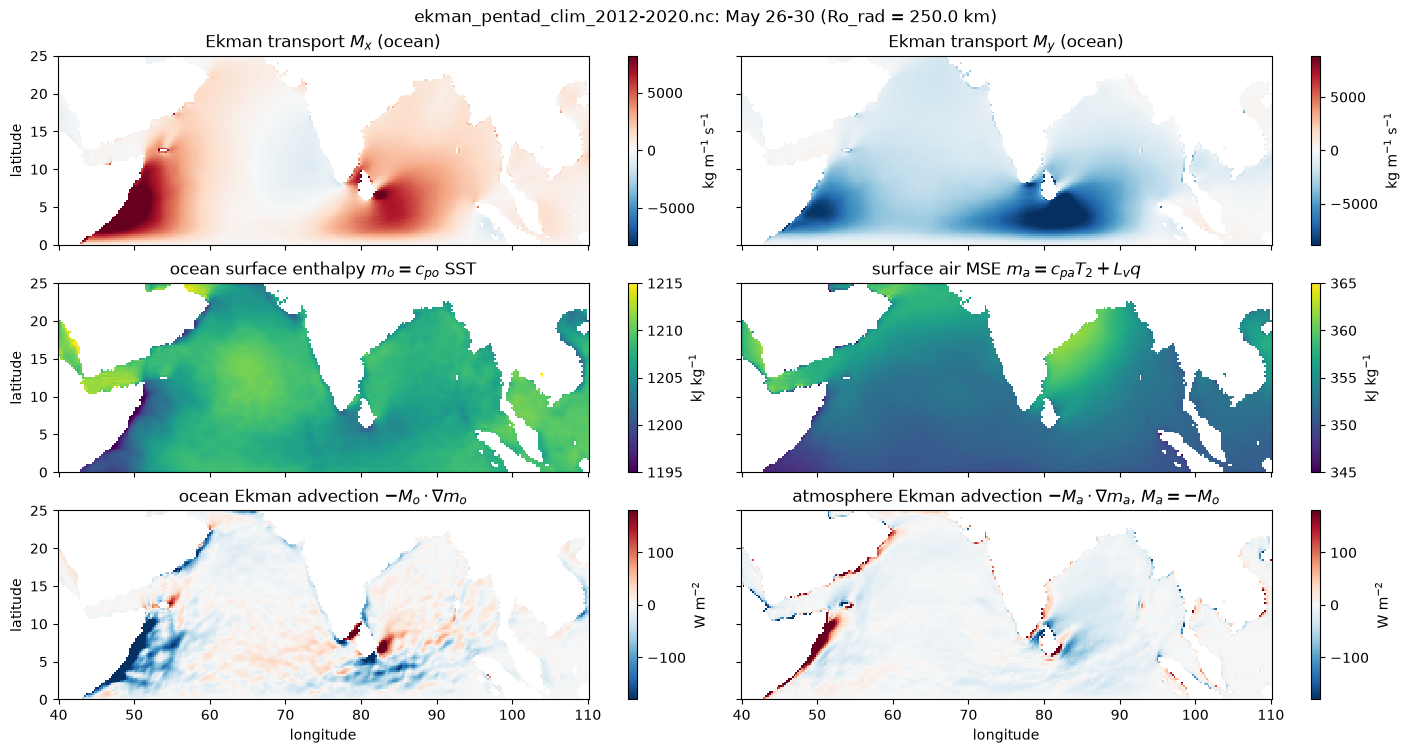

In [9]:
panels1 = [
    panel(f.Mx, raw"Ekman transport $M_x$ (ocean)", raw"kg m$^{-1}$ s$^{-1}$"),
    panel(f.My, raw"Ekman transport $M_y$ (ocean)", raw"kg m$^{-1}$ s$^{-1}$"),
    panel(f.m_o ./ 1e3, raw"ocean surface enthalpy $m_o = c_{po}$ SST", raw"kJ kg$^{-1}$"; cmap="viridis", vmin=1195, vmax=1215),
    panel(f.m_a ./ 1e3, raw"surface air MSE $m_a = c_{pa} T_2 + L_v q$", raw"kJ kg$^{-1}$"; cmap="viridis", vmin=345, vmax=365),
    panel(f.adv_o, raw"ocean Ekman advection $-M_o \cdot \nabla m_o$", flux_units; vmin=-advlim, vmax=advlim),
    panel(f.adv_a, raw"atmosphere Ekman advection $-M_a \cdot \nabla m_a$, $M_a = -M_o$", flux_units; vmin=-advlim, vmax=advlim)
    ]    
fig1, axs1 = plot_panels(f.lon, f.lat, panels1; land=f.land, suptitle=figtitle);
for ax in axs1.flat
    ax.set_ylim(latlim...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig1.savefig("ekman_V_ma_mo_pentad$p.png")

Atmosphere and ocean (moist) enthalpy color ranges are both 20 kJ/kg. The atmosphere has a gradient in the Bay of Bengal, but not much in the Arabian Sea. Theres a maximum (SST) in the central AS. Atmosphere and Ocean have nearly opposite MSE gradients around 20 N in the Arabian Sea. Both gradients result in cool advection, because of the southward ocean and northward atmosphere Ekman transport.

In [6]:
# figures display at the end of the cell that makes them; to adjust the axes and show it again:
# axs1[0, 0].set_xlim(50, 100); axs1[0, 0].set_ylim(-5, 25); display(fig1)

## Ocean and atmosphere Ekman advection and their sum
Columns: ocean, atmosphere, sum. Rows: temperature (SST, $T_2$; mass-weighted, K kg m$^{-2}$ s$^{-1}$), and enthalpy (ocean $m_o$) and moist enthalpy (atmosphere $m_a$), W m$^{-2}$. Each row shares its color limits. Uses `advlim` from the cell above.

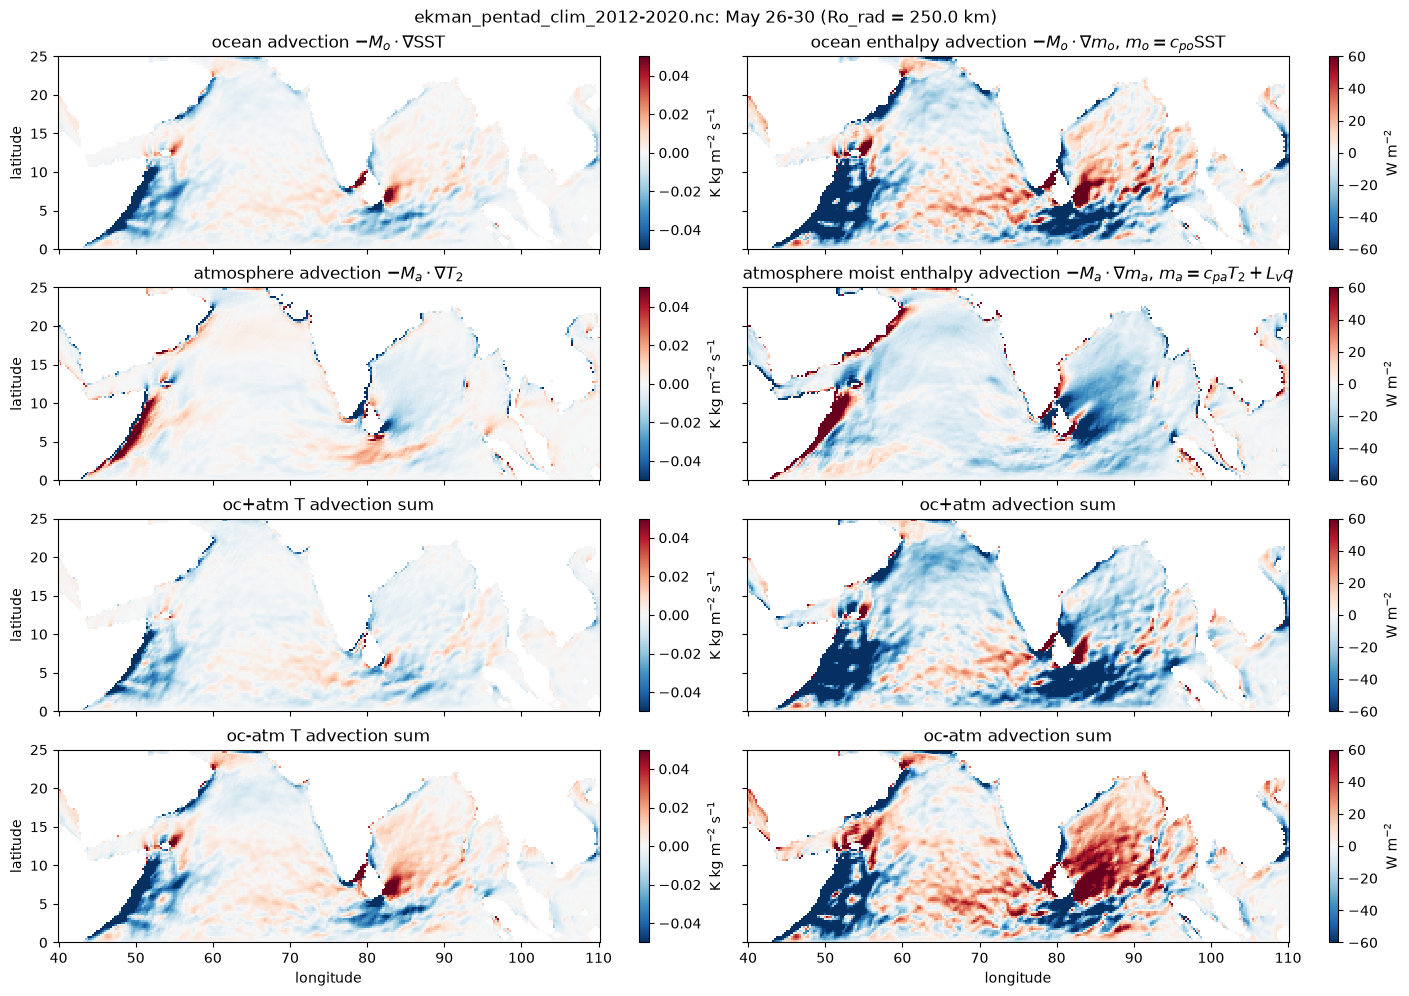

In [20]:
Tlim = 0.05 # maximum(symlim, (f.advT_o, f.advT_a)) # shared by the temperature row
Hlim = 60                               # W m^-2, shared by the enthalpy row
panels_adv = [
    panel(f.advT_o, raw"ocean advection $-M_o \cdot \nabla$SST", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.adv_o, raw"ocean enthalpy advection $-M_o \cdot \nabla m_o$, $m_o = c_{po}$SST", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f.advT_a, raw"atmosphere advection $-M_a \cdot \nabla T_2$", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.adv_a, raw"atmosphere moist enthalpy advection $-M_a \cdot \nabla m_a$, $m_a = c_{pa}T_2 + L_v q$", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f.advT_o .+ f.advT_a, "oc+atm T advection sum", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.adv_o .+ f.adv_a, "oc+atm advection sum", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f.advT_o .- f.advT_a, "oc-atm T advection sum", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.adv_o .- f.adv_a, "oc-atm advection sum", flux_units; vmin=-Hlim, vmax=Hlim)
    ]
fig_adv, axs_adv = plot_panels(f.lon, f.lat, panels_adv; ncols=2, land=f.land, suptitle=figtitle);
for ax in axs_adv.flat
    ax.set_ylim(latlim...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig_adv.savefig("ekman_adv_sum_pentad$p.png")

Differnece plot (lowest right) shows examples of 2 regimes: 

(red) Ekman advection warms ocean relative to atmosphere. This reflects atmospheric cooling advection by baroclinic frictional wind, which flows down pressure gradients from cool T to warmer T. 
This is expected for SST driving the surface wind response in the atmosphere.

(blue) Ekamn advection cools ocean relative to atmosphere. This reflects ocean cooling by advection out of cool regions of SST by Ekman divergence and upwelling. 
This is the expected for wind stress driving the surface temperature response in the ocean.

## Cancellation of Ekman divergence and flux divergence tendency
So use advection form.

Columns: ocean, atmosphere. The flux form $-\nabla\cdot(M m)$ is from the saved composites of $s\tau_x$, $s\tau_y$; $m \nabla\cdot M = $ adv $-$ flux. m is measured from 0 K, so $m \nabla\cdot M$ is large and nearly cancels in the flux form.

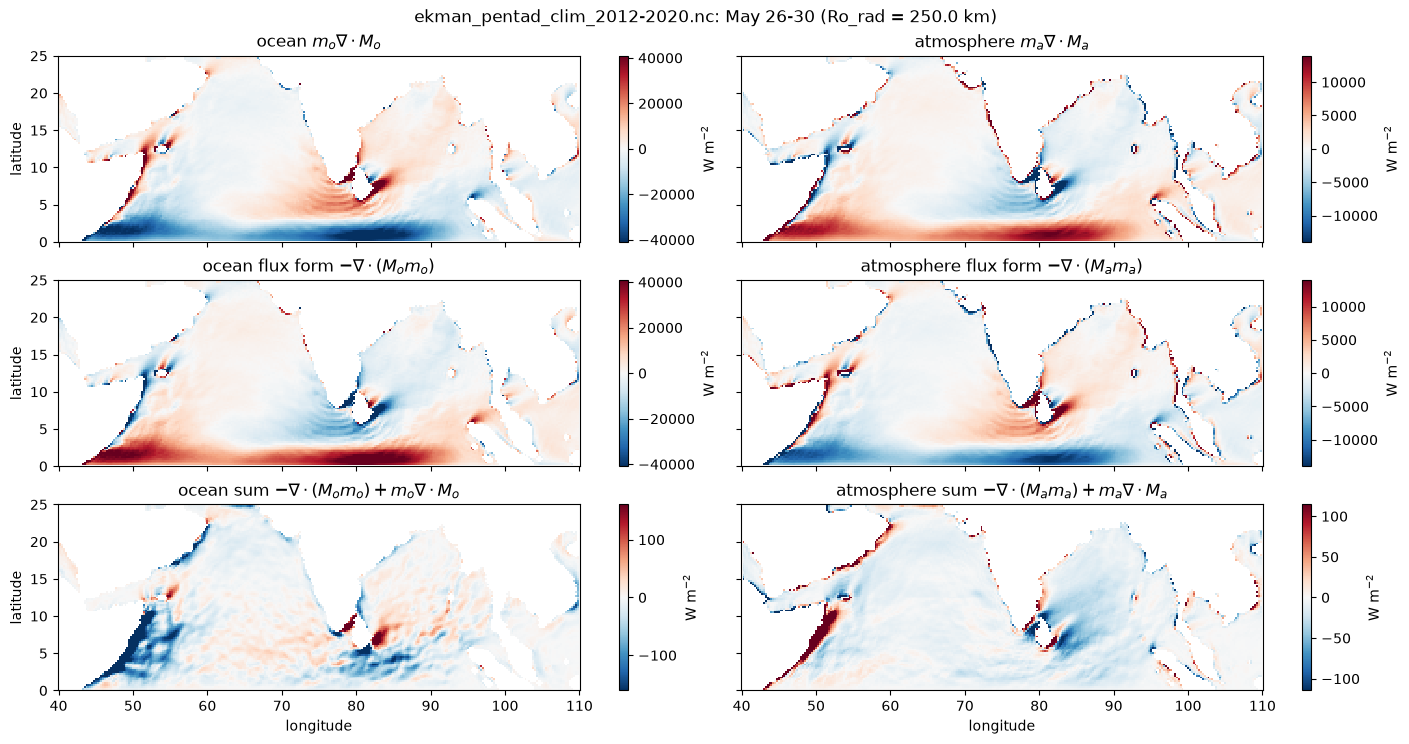

In [11]:
panels3 = [
    panel(f.sdiv_o, raw"ocean $m_o \nabla \cdot M_o$", flux_units),
    panel(f.sdiv_a, raw"atmosphere $m_a \nabla \cdot M_a$", flux_units),
    panel(f.flux_o, raw"ocean flux form $-\nabla \cdot (M_o m_o)$", flux_units),
    panel(f.flux_a, raw"atmosphere flux form $-\nabla \cdot (M_a m_a)$", flux_units),
    panel(f.flux_o.+f.sdiv_o, raw"ocean sum $-\nabla \cdot (M_o m_o) + m_o \nabla \cdot M_o$", flux_units),
    panel(f.flux_a.+f.sdiv_a, raw"atmosphere sum $-\nabla \cdot (M_a m_a) + m_a \nabla \cdot M_a$", flux_units)]
fig3, axs3 = plot_panels(f.lon, f.lat, panels3; land=f.land, suptitle=figtitle);
for ax in axs3.flat
    ax.set_ylim(latlim...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig3.savefig("ekman_sdiv_flux_pentad$p.png")